<div dir="rtl">

# الحلقة 2: الـ Reward والـ Return والـ Discounting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mmmohamedaaashraf/deep-rl-arabic/blob/main/ep02-discounting/ep02_discounting.ipynb)

**سلسلة Deep RL بالعربي**، مبنية على [كورس Hugging Face Deep RL](https://huggingface.co/learn/deep-rl-course) (Unit 1: The RL Framework + The type of tasks)،
ومدعومة بالفصل التالت من كتاب Sutton & Barto: *Reinforcement Learning: An Introduction* (2nd ed.).

### إحنا فين؟
- **الحلقة 1:** الـ RL loop: الـ agent بياخد state، يختار action، والـ environment يرجعله reward و state جديدة. جربنا agent عشوائي على LunarLander فوقع بـ 351- نقطة.
- **النهارده:** هدف الـ agent بالظبط إيه؟ يعني إيه return؟ وليه الـ reward اللي جاي بعدين قيمته أقل (discounting)؟ وإيه الفرق بين episodic و continuing tasks؟
- **الحلقة الجاية:** Exploration vs Exploitation.

**على Colab:** `Runtime > Run all`.
</div>

<div dir="rtl">

## 0) التجهيز
</div>

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "swig"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]", "stable-baselines3"], check=True)

import os, urllib.request
import numpy as np, matplotlib.pyplot as plt, gymnasium as gym
from stable_baselines3 import PPO
print("gymnasium", gym.__version__)

gymnasium 1.4.0


<div dir="rtl">

## 1) ريكاب سريع: نفس الحلقة اللي المركبة وقعت فيها
هنعمل function واحدة بتلعب حلقة كاملة بأي policy، وترجع كل الـ rewards. وهنستخدمها طول النوتبوك.
</div>

In [2]:
def run_episode(policy, seed, env_id="LunarLander-v3"):
    """Play one full episode. policy(obs) -> action. Returns the list of rewards R1, R2, ..., RT."""
    env = gym.make(env_id)
    obs, _ = env.reset(seed=seed)
    env.action_space.seed(seed)
    rewards, actions, done = [], [], False
    while not done:
        a = policy(obs, env)
        obs, r, terminated, truncated, _ = env.step(a)
        rewards.append(float(r)); actions.append(int(a))
        done = terminated or truncated
    env.close()
    return np.array(rewards), np.array(actions)

random_policy = lambda obs, env: env.action_space.sample()

rewards_crash, _ = run_episode(random_policy, seed=42)
print(f"steps        : {len(rewards_crash)}")
print(f"last reward  : {rewards_crash[-1]:+.1f}   <- the crash")
print(f"sum of rewards: {rewards_crash.sum():+.1f}")

steps        : 123
last reward  : -100.0   <- the crash
sum of rewards: -351.2


<div dir="rtl">

## 2) الـ Reward: الإشارة الوحيدة اللي الـ agent بيتعلم منها
في LunarLander، الـ reward في كل خطوة بيتحسب كده (من Gymnasium docs):
- بيزيد كل ما المركبة تقرب من منطقة الهبوط، وتبطّأ، وتفضل معدولة.
- **+10** لكل رجل تلمس الأرض.
- **0.3-** كل frame الموتور الرئيسي شغال، و**0.03-** للموتور الجانبي (ده تمن البنزين).
- في الآخر: **100-** لو وقعت، أو **+100** لو هبطت بأمان.
- الحلقة تعتبر محلولة لو مجموعها **200** أو أكتر.
</div>

In [3]:
spec = gym.spec("LunarLander-v3")
print("max_episode_steps :", spec.max_episode_steps)
print("reward_threshold  :", spec.reward_threshold)
print("render fps        :", gym.make("LunarLander-v3").metadata["render_fps"])

max_episode_steps : 1000
reward_threshold  : 200
render fps        : 50


<div dir="rtl">

## 3) مين الـ PPO ده؟ الفرق بينه وبين الـ agent العشوائي
في الحلقة دي هنقارن agent عشوائي بـ agent متدرب اسمه **PPO**. قبل المقارنة لازم نفهم هو إيه.

- **الـ agent العشوائي** مالوش أي "مخ": كل action من الأربعة ليها فرصة **25%**، مهما كان الـ state.
- **الـ PPO agent** جواه neural network صغيرة اسمها **policy**: بتاخد الـ state (8 أرقام: المكان، السرعة، الزاوية، والرجلين لمسوا الأرض ولا لأ)
  وتطلع **احتمال لكل action**. يعني بيختار حسب الموقف اللي هو فيه.

الأربع actions في LunarLander: `0` ماتعملش حاجة · `1` الموتور الجانبي الشمال · `2` الموتور الرئيسي · `3` الموتور الجانبي اليمين.

هنحمّل الموديل اللي دربناه في آخر الحلقة 1 ونبص جواه.
</div>

In [4]:
MODEL = "ppo-LunarLander-v3.zip"
if not os.path.exists(MODEL):
    urllib.request.urlretrieve("https://github.com/mmmohamedaaashraf/deep-rl-arabic/raw/main/ep01-what-is-rl/" + MODEL, MODEL)
model = PPO.load(MODEL)

print(model.policy)   # the network: 8 inputs -> 64 -> 64 -> 4 actions (+ a value head)
n_params = sum(p.numel() for p in model.policy.parameters())
print("parameters:", n_params)

ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=8, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=4, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)
parameters: 9797


<div dir="rtl">

**نقرا الـ output:**
- `policy_net`: طبقتين، كل واحدة 64 neuron و `Tanh`. ده الجزء اللي بيفكر.
- `action_net`: من 64 لـ **4**: رقم لكل action، وبيتحولوا لاحتمالات.
- `value_net`: من 64 لـ **1**: تقدير الـ return من الـ state دي (هنفهمه في الحلقات الجاية: الـ value function). وليه طبقتين لوحده جوه `mlp_extractor`.
- المجموع **9,797** رقم (parameters)، نصهم تقريبًا للـ policy ونصهم للـ value. صغيرة جدًا، وكفاية تهبط المركبة.

خلينا نشوف الاحتمالات دي بعينينا في أول لحظة من حلقة (seed 44)، ونقارنها بالعشوائي:
</div>

state (8 numbers): [ 0.007  1.421  0.711  0.432 -0.008 -0.161  0.     0.   ]
do nothing    random = 25.0%   PPO =  24.5%
left engine   random = 25.0%   PPO =  75.4%
main engine   random = 25.0%   PPO =   0.0%
right engine  random = 25.0%   PPO =   0.1%


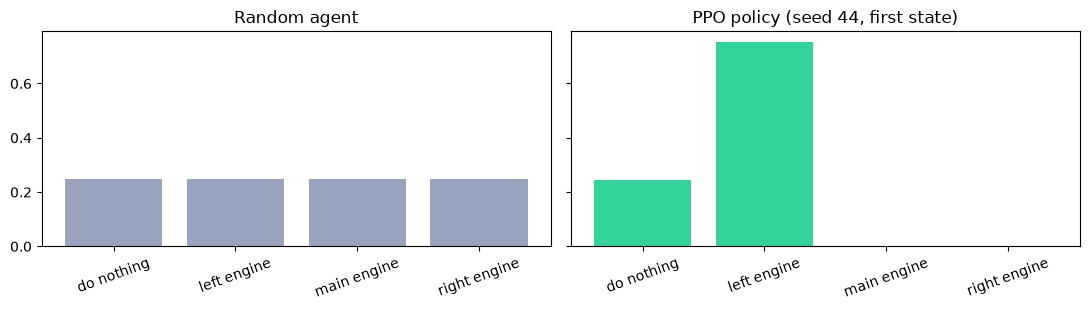

In [5]:
import torch
ACTIONS = ["do nothing", "left engine", "main engine", "right engine"]

env = gym.make("LunarLander-v3")
obs44, _ = env.reset(seed=44)
env.close()
print("state (8 numbers):", np.round(obs44, 3))

obs_t, _ = model.policy.obs_to_tensor(obs44)
with torch.no_grad():
    probs = model.policy.get_distribution(obs_t).distribution.probs[0].cpu().numpy()

for name, p in zip(ACTIONS, probs):
    print(f"{name:13s} random = 25.0%   PPO = {100 * p:5.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
ax[0].bar(ACTIONS, [0.25] * 4, color="#9AA3BD"); ax[0].set_title("Random agent")
ax[1].bar(ACTIONS, probs, color="#34D399");     ax[1].set_title("PPO policy (seed 44, first state)")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

<div dir="rtl">

### الـ PPO اتعلم إزاي؟ (الفكرة بس، والتفاصيل في Unit 8)
**PPO = Proximal Policy Optimization.** الموديل ده لعب LunarLander **مليون خطوة** (16 نسخة من اللعبة في نفس الوقت). وفي كل دورة:
1. يلعب **دفعة** خطوات بالـ policy الحالية.
2. يشوف كل action جابت نتيجة **أحسن ولا أوحش من المتوقع** (اسمها advantage).
3. يعدّل الـ network **شوية**: يزوّد احتمال الـ actions اللي طلعت أحسن من المتوقع، ويقلل اللي طلعت أوحش.

**Proximal = قريب:** التعديل في كل دورة بيتقص (clip) عشان الـ policy الجديدة تفضل قريبة من القديمة (نسبة التغيير بين 0.8 و 1.2).
لو سبناه يقفز قفزة كبيرة، ممكن يبوّظ كل اللي اتعلمه في خطوة واحدة.

الكود اللي درّب الموديل ده (موجود في فولدر الحلقة 1، وبياخد حوالي 20 دقيقة على CPU، **ماتشغلوش دلوقتي**):
```python
env = make_vec_env("LunarLander-v3", n_envs=16)
model = PPO("MlpPolicy", env, n_steps=1024, batch_size=64, n_epochs=4,
            gamma=0.999, gae_lambda=0.98, ent_coef=0.01)
model.learn(total_timesteps=1_000_000)
```
لاحظ `gamma=0.999`: هنفهم الرقم ده كويس في الحلقة دي.

### الفرق في الكود: سطر واحد
```python
action = env.action_space.sample()               # random: a coin flip, ignores obs
action, _ = model.predict(obs, deterministic=True)  # PPO: asks the network about this obs
```
`deterministic=True` معناها: اختار الـ action اللي احتمالها أعلى (مش بالقرعة).

**إزاي نشوف الفرق؟** نشغّل الاتنين على **نفس الحلقات** (نفس الـ seeds) ونقارن الأرقام. وده اللي جاي.
</div>

<div dir="rtl">

## 4) ليه الهدف هو **مجموع** الـ rewards مش الـ reward اللي دلوقتي؟
نقارن 3 agents على نفس الـ 100 حلقة:
1. **عشوائي.**
2. **"بخيل":** عمره ما يشغّل الموتور، عشان ميخسرش ولا نقطة بنزين دلوقتي. يعني بيحاول يكسب في اللحظة دي بس.
3. **PPO متدرب** (اللي لسه شايفينه من جوه).
</div>

In [6]:
agents = {
    "random": random_policy,
    "no-engine (greedy)": lambda obs, env: 0,
    "trained PPO": lambda obs, env: int(model.predict(obs, deterministic=True)[0]),
}
stats = {}
for name, pol in agents.items():
    totals, fuel, landed = [], [], 0
    for seed in range(100):
        r, a = run_episode(pol, seed)
        totals.append(r.sum())
        fuel.append(-(0.3 * (a == 2).sum() + 0.03 * np.isin(a, [1, 3]).sum()))
        landed += r[-1] == 100
    stats[name] = (np.mean(totals), np.mean(fuel), landed)
    print(f"{name:20s} mean return = {np.mean(totals):+7.1f} | mean fuel cost = {np.mean(fuel):+6.1f} | safe landings = {landed}/100")

random               mean return =  -191.0 | mean fuel cost =   -8.1 | safe landings = 0/100
no-engine (greedy)   mean return =  -136.7 | mean fuel cost =   +0.0 | safe landings = 0/100


trained PPO          mean return =  +238.4 | mean fuel cost =  -72.4 | safe landings = 100/100


<div dir="rtl">

**الملاحظة المهمة:** الـ PPO بيدفع تمن بنزين أكتر من الكل (خسارة **دلوقتي**)، عشان يكسب الهبوط الآمن **بعدين**.
والـ agent "البخيل" اللي بيفكر في اللحظة دي بس، بيقع.
عشان كده هدف الـ agent هو الـ **return**: مجموع الـ rewards لحد آخر الحلقة، مش الـ reward اللي في إيده دلوقتي.
</div>

<div dir="rtl">

## 5) الـ Return والـ Discounting
الـ return من اللحظة t:

$$G_t = R_{t+1} + R_{t+2} + \dots + R_T$$

بس فيه 3 مشاكل لو جمعنا كله بنفس الوزن:
1. **المستقبل مش مضمون:** الـ reward اللي بعيد ممكن مايحصلش أصلًا (مثال الفار والقطة في الكورس).
2. **فلوس النهارده أحسن من فلوس بكرة:** "cash now is better than cash later" (OpenAI Spinning Up).
3. **المهام اللي مالهاش نهاية:** الجمع ممكن يطلع ما لانهاية.

الحل: نضرب كل reward في γ (gamma) أُس بُعده عننا:

$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}, \qquad 0 \le \gamma \le 1$$
</div>

In [7]:
def discounted_return(rewards, gamma):
    """G0 = R1 + gamma*R2 + gamma^2*R3 + ..."""
    weights = gamma ** np.arange(len(rewards))
    return float(np.sum(weights * rewards))

GAMMAS = [1.0, 0.999, 0.99, 0.9, 0.5]
print("Same crash episode, different gamma:")
for g in GAMMAS:
    w_last = g ** (len(rewards_crash) - 1)
    print(f"gamma={g:<6} G0 = {discounted_return(rewards_crash, g):+8.1f}   | weight of the -100 crash = {w_last:.3f}")

Same crash episode, different gamma:
gamma=1.0    G0 =   -351.2   | weight of the -100 crash = 1.000
gamma=0.999  G0 =   -319.7   | weight of the -100 crash = 0.885
gamma=0.99   G0 =   -145.2   | weight of the -100 crash = 0.293
gamma=0.9    G0 =     -3.7   | weight of the -100 crash = 0.000
gamma=0.5    G0 =     +0.7   | weight of the -100 crash = 0.000


<div dir="rtl">

**نفس الحلقة بالظبط**، بس الـ γ غيّر الصورة خالص: مع γ = 0.9 الوقعة اللي في الآخر تقريبًا ملهاش وزن، فالـ agent "مش شايفها".
</div>

<div dir="rtl">

## 6) الـ γ معناه إيه عمليًا؟ الـ effective horizon
الوزن بتاع reward بعد k خطوة هو γ^k. والـ agent عمليًا "بيشوف" لقدام حوالي **1/(1-γ)** خطوة.
</div>

 gamma | horizon 1/(1-g) | seconds in LunarLander
   0.5 |               2 |                   0.04
   0.9 |              10 |                   0.20
  0.99 |             100 |                   2.00
 0.999 |            1000 |                  20.00


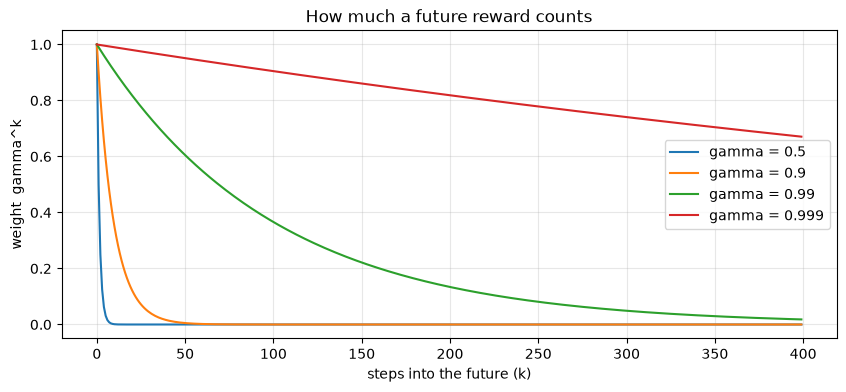

In [8]:
fps = 50  # LunarLander runs at 50 frames per second
print(f"{'gamma':>6} | {'horizon 1/(1-g)':>15} | {'seconds in LunarLander':>22}")
for g in [0.5, 0.9, 0.99, 0.999]:
    h = 1 / (1 - g)
    print(f"{g:>6} | {h:>15.0f} | {h / fps:>22.2f}")

k = np.arange(0, 400)
plt.figure(figsize=(10, 4))
for g in [0.5, 0.9, 0.99, 0.999]:
    plt.plot(k, g ** k, label=f"gamma = {g}")
plt.xlabel("steps into the future (k)"); plt.ylabel("weight  gamma^k")
plt.title("How much a future reward counts"); plt.legend(); plt.grid(alpha=.3)
plt.show()

<div dir="rtl">

- γ = 0.99 (القيمة الافتراضية في الكورس) يعني الـ agent شايف حوالي 100 خطوة = **2 ثانية** بس في LunarLander.
- عشان كده الكورس بيدرّب PPO على LunarLander بـ **γ = 0.999** (حوالي 1000 خطوة = 20 ثانية): الهبوط بياخد مئات الخطوات، والـ +100 بتاعة الهبوط بتيجي في الآخر.
</div>

<div dir="rtl">

## 7) نفس المعادلة بشكل recursive (ودي أهم سطر في النوتبوك)

$$G_t = R_{t+1} + \gamma\, G_{t+1}$$

يعني الـ return من دلوقتي = الـ reward الجاي + γ × الـ return من الخطوة اللي بعدها.
ده بيخلينا نحسب الـ return لكل لحظة في الحلقة في **لفة واحدة من الآخر للأول**، وهي نفس الفكرة اللي هتبني عليها الـ Bellman equation في الحلقات الجاية.
</div>

In [9]:
def returns_to_go(rewards, gamma):
    """G_t for every t, computed backwards with G_t = R_{t+1} + gamma * G_{t+1}."""
    G = np.zeros(len(rewards))
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        G[t] = running
    return G

g = 0.99
G_crash = returns_to_go(rewards_crash, g)
print(f"recursive G0 = {G_crash[0]:+.4f}")
print(f"direct    G0 = {discounted_return(rewards_crash, g):+.4f}   <- same number")

recursive G0 = -145.1667
direct    G0 = -145.1667   <- same number


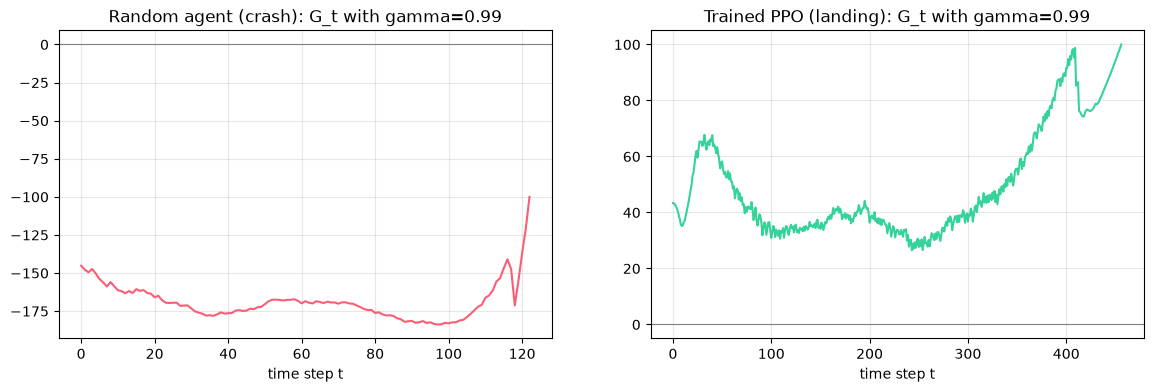

random (crash)  : 123 steps | G0 (gamma=0.99) =  -145.2 | no discount =  -351.2
PPO    (landing): 457 steps | G0 (gamma=0.99) =   +43.4 | no discount =  +269.6
PPO landing with gamma=0.999: G0 = +202.6
weight of the +100 landing bonus at the start: gamma=0.99 -> 0.010, gamma=0.999 -> 0.634


In [10]:
r_land, _ = run_episode(agents["trained PPO"], seed=44)
G_land = returns_to_go(r_land, g)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(G_crash, color="#FB5D74"); ax[0].set_title(f"Random agent (crash): G_t with gamma={g}")
ax[1].plot(G_land, color="#34D399");  ax[1].set_title(f"Trained PPO (landing): G_t with gamma={g}")
for a in ax: a.set_xlabel("time step t"); a.axhline(0, color="gray", lw=.8); a.grid(alpha=.3)
plt.show()
print(f"random (crash)  : {len(rewards_crash):3d} steps | G0 (gamma=0.99) = {G_crash[0]:+7.1f} | no discount = {rewards_crash.sum():+7.1f}")
print(f"PPO    (landing): {len(r_land):3d} steps | G0 (gamma=0.99) = {G_land[0]:+7.1f} | no discount = {r_land.sum():+7.1f}")
print(f"PPO landing with gamma=0.999: G0 = {discounted_return(r_land, 0.999):+.1f}")
print(f"weight of the +100 landing bonus at the start: gamma=0.99 -> {0.99 ** (len(r_land) - 1):.3f}, gamma=0.999 -> {0.999 ** (len(r_land) - 1):.3f}")

<div dir="rtl">

الرسمة دي بتقولك "من اللحظة دي، المستقبل شكله عامل إزاي؟". في الحلقة العشوائية الـ G_t بينزل جامد قبل الوقعة، وفي الـ PPO بيفضل موجب.
الرقم ده بالظبط هو اللي الـ agent هيتعلم **يتوقعه** بعدين، واسمه **value function**.
</div>

<div dir="rtl">

## 8) تجربة: الـ γ بيغيّر القرار نفسه
ممر فيه 6 خانات. الـ agent واقف في النص:
- **شمال:** جبنة صغيرة (+1) على بعد **خطوة واحدة**.
- **يمين:** جبنة كبيرة (+10) على بعد **5 خطوات**.

أنهي أحسن؟ الإجابة بتعتمد على γ.
</div>

In [11]:
class Corridor:
    """Tiny episodic environment: [+1] . A . . . . [+10]. Action 0 = left, 1 = right."""
    def __init__(self):
        self.left_end, self.right_end = 0, 6
    def reset(self):
        self.pos = 1
        return self.pos
    def step(self, action):
        self.pos += -1 if action == 0 else 1
        if self.pos == self.left_end:  return self.pos, 1.0, True
        if self.pos == self.right_end: return self.pos, 10.0, True
        return self.pos, 0.0, False

def play(plan_action):
    env, rewards, done = Corridor(), [], False
    env.reset()
    while not done:
        _, r, done = env.step(plan_action)
        rewards.append(r)
    return np.array(rewards)

r_left, r_right = play(0), play(1)
print("left  rewards:", r_left)
print("right rewards:", r_right)
print()
for gm in [0.3, 0.5, 0.56, 0.6, 0.9, 0.99]:
    gl, gr = discounted_return(r_left, gm), discounted_return(r_right, gm)
    print(f"gamma={gm:<5} G(left)={gl:5.2f}  G(right)={gr:5.2f}  -> best: {'LEFT  (+1 now)' if gl > gr else 'RIGHT (+10 later)'}")
print(f"\nswitch point: 10 * gamma^4 = 1  ->  gamma = {0.1 ** 0.25:.3f}")

left  rewards: [1.]
right rewards: [ 0.  0.  0.  0. 10.]

gamma=0.3   G(left)= 1.00  G(right)= 0.08  -> best: LEFT  (+1 now)
gamma=0.5   G(left)= 1.00  G(right)= 0.62  -> best: LEFT  (+1 now)
gamma=0.56  G(left)= 1.00  G(right)= 0.98  -> best: LEFT  (+1 now)
gamma=0.6   G(left)= 1.00  G(right)= 1.30  -> best: RIGHT (+10 later)
gamma=0.9   G(left)= 1.00  G(right)= 6.56  -> best: RIGHT (+10 later)
gamma=0.99  G(left)= 1.00  G(right)= 9.61  -> best: RIGHT (+10 later)

switch point: 10 * gamma^4 = 1  ->  gamma = 0.562


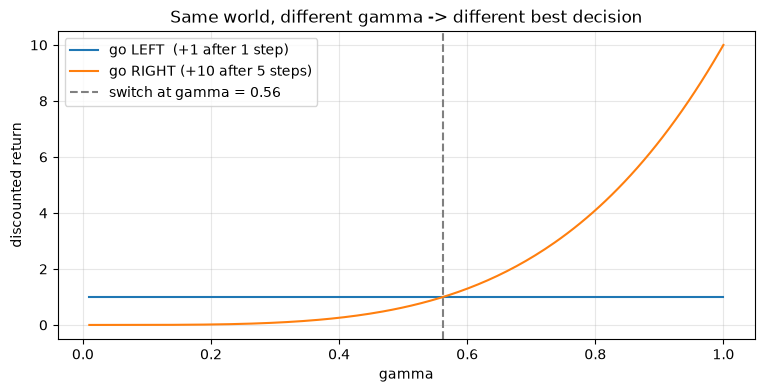

In [12]:
gs = np.linspace(0.01, 1, 200)
plt.figure(figsize=(9, 4))
plt.plot(gs, [discounted_return(r_left, x) for x in gs], label="go LEFT  (+1 after 1 step)")
plt.plot(gs, [discounted_return(r_right, x) for x in gs], label="go RIGHT (+10 after 5 steps)")
plt.axvline(0.1 ** 0.25, color="gray", ls="--", label=f"switch at gamma = {0.1 ** 0.25:.2f}")
plt.xlabel("gamma"); plt.ylabel("discounted return"); plt.legend(); plt.grid(alpha=.3)
plt.title("Same world, different gamma -> different best decision")
plt.show()

<div dir="rtl">

## 9) Episodic ولا Continuing؟ وليه γ بيفرق هنا
- **Episodic task:** ليها بداية ونهاية (terminal state). LunarLander بتخلص لما المركبة تقع، أو تهبط وتقف، أو تطلع برة الشاشة، أو توصل لأقصى عدد خطوات.
- **Continuing task:** مالهاش نهاية، زي agent بيعمل trading أو بيتحكم في تكييف مبنى طول الوقت.

في الـ continuing task لو كل خطوة فيها reward = +1، الجمع من غير discount بيروح لما لانهاية، لكن مع γ < 1 بيوصل لرقم ثابت = **1/(1-γ)**.
</div>

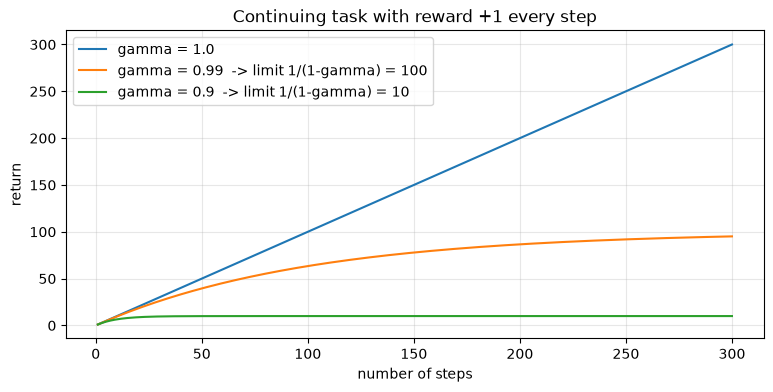

gamma=0.9: after 300 steps G = 10.00, limit = 10
gamma=0.99: after 300 steps G = 95.10, limit = 100


In [13]:
steps = np.arange(1, 301)
plt.figure(figsize=(9, 4))
for gm in [1.0, 0.99, 0.9]:
    partial = np.cumsum(gm ** (steps - 1))  # reward +1 every step
    plt.plot(steps, partial, label=f"gamma = {gm}" + ("" if gm == 1 else f"  -> limit 1/(1-gamma) = {1/(1-gm):.0f}"))
plt.xlabel("number of steps"); plt.ylabel("return"); plt.legend(); plt.grid(alpha=.3)
plt.title("Continuing task with reward +1 every step")
plt.show()
for gm in [0.9, 0.99]:
    print(f"gamma={gm}: after 300 steps G = {np.sum(gm ** np.arange(300)):.2f}, limit = {1/(1-gm):.0f}")

<div dir="rtl">

## الخلاصة
1. الـ **reward** هو الإشارة الوحيدة اللي الـ agent بيتعلم منها، وبيقول **إيه** المطلوب مش **إزاي** يتعمل.
2. **Reward hypothesis:** أي هدف ممكن يتوصف إنه تعظيم الـ expected return.
3. الـ **return** هو مجموع الـ rewards من دلوقتي لآخر الحلقة. ومين يفكر في اللحظة بس (الـ agent البخيل) بيقع.
4. الـ **discounting** بيدي المستقبل وزن أقل بـ γ^k: بيعبر عن عدم اليقين، وبيخلي الجمع محدود في الـ continuing tasks.
5. الـ γ بيحدد الـ agent بيشوف لقدام قد إيه (~1/(1-γ) خطوة)، وممكن **يغيّر القرار نفسه**.
6. **G_t = R_{t+1} + γ G_{t+1}**: الأساس اللي هنبني عليه الـ value function والـ Bellman equation.

**جرّب بنفسك:**
- غيّر مكان الجبنة الكبيرة في الـ Corridor لـ 10 خطوات، واحسب نقطة التحول الجديدة.
- احسب الـ return لحلقة الـ PPO بـ γ = 0.9، وقارنه بـ 0.999.

**المراجع:**
- Hugging Face Deep RL Course, Unit 1: The RL Framework / The type of tasks
- Sutton & Barto, *Reinforcement Learning: An Introduction* (2nd ed.), Chapter 3.2 – 3.4
- OpenAI Spinning Up, Part 1: Key Concepts in RL
- Gymnasium docs: LunarLander

عندك سؤال؟ اكتبه في كومنت على الفيديو:
[LinkedIn](https://www.linkedin.com/in/mohamed-ashraf0) · [Facebook](https://www.facebook.com/MohamedAshrafIN) · [YouTube](https://www.youtube.com/@MmmohamedAaashraf)
</div>